[Open in Colab](https://colab.research.google.com/github/yueliosu/yueliphd.net/blob/main/tutorials/coms930/visual-feature-extraction.ipynb){.btn .btn-primary .btn-sm} [Download notebook (.ipynb)](visual-feature-extraction.ipynb){.btn .btn-outline-primary .btn-sm}

::: {.callout-note appearance="simple"}
Runs as is with an example image from Wikimedia Commons.
:::

COMS 930 – Computational Methods

This notebook demonstrates how computers extract visual features from images.
We will:

1. Load an image
2. Detect keypoints
3. Inspect feature vectors (descriptors)
4. Cluster descriptors into visual words
5. Visualize the clusters


In [ ]:
!pip -q install opencv-python matplotlib scikit-learn

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from urllib.request import urlopen, Request
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

## Load an Example Image

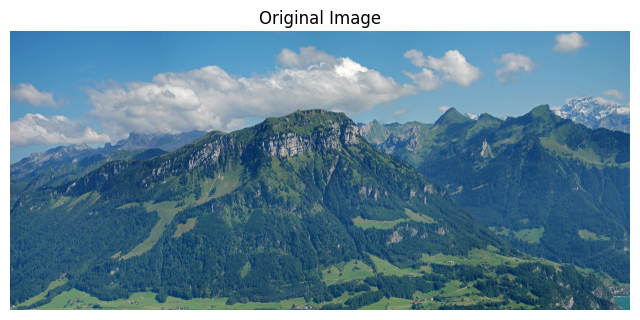

In [ ]:
url = 'https://upload.wikimedia.org/wikipedia/commons/3/3f/Fronalpstock_big.jpg'
req = Request(url, headers={'User-Agent': 'Mozilla/5.0'})
img_array = np.asarray(bytearray(urlopen(req).read()), dtype=np.uint8)
img = cv2.imdecode(img_array, cv2.IMREAD_COLOR)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8,6))
plt.imshow(img)
plt.axis('off')
plt.title('Original Image')
plt.show()

## Detect Visual Keypoints (Feature Extraction)

Keypoints are visually informative locations such as corners, edges, and texture changes.

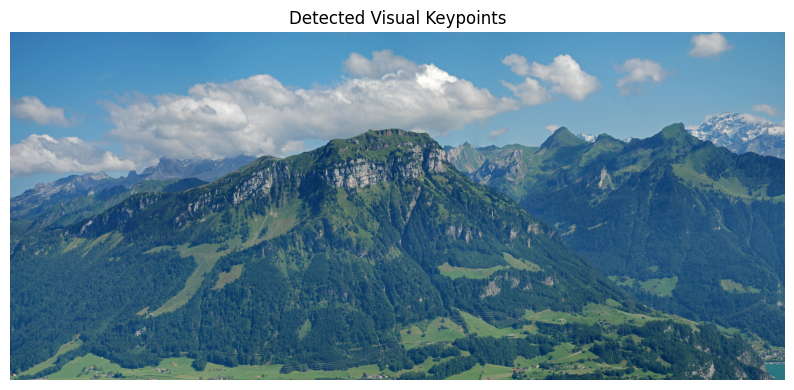

In [ ]:
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

orb = cv2.ORB_create(nfeatures=500)
keypoints, descriptors = orb.detectAndCompute(gray, None)

img_keypoints = cv2.drawKeypoints(img, keypoints, None, color=(0,255,0), flags=0)

plt.figure(figsize=(10,7))
plt.imshow(img_keypoints)
plt.axis('off')
plt.title('Detected Visual Keypoints')
plt.show()

## Inspect the Feature Vectors

For each keypoint, ORB computes a **descriptor**. This is a numerical summary of the local visual pattern around that keypoint.

- Rows = keypoints
- Columns = descriptor values

In other words, each row is a **feature vector**.

In [ ]:
print('Number of keypoints:', len(keypoints))
print('Descriptor matrix shape:', descriptors.shape)
print('\nFirst feature vector:')
print(descriptors[0])

Number of keypoints: 500
Descriptor matrix shape: (500, 32)

First feature vector:
[212  49 187  96 248 108 113  80 186 141 231  24  22 151  65  58 176  60
  76  56  50 211 176   2 219 161  32 108 128  33  38  99]


## What Does This Mean?

If the output shape is, for example, `(500, 32)`, that means:

- the algorithm found **500 keypoints**
- each keypoint is represented by a **32-number feature vector**

These numbers summarize local edge and texture structure near the keypoint.

## Cluster the Feature Vectors into “Visual Words”

A Bag-of-Visual-Words approach groups similar feature vectors together.

Each cluster can be treated as a **visual word**.

In [ ]:
k = 8  # number of visual words for a simple demo
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(descriptors)

print('Cluster counts (visual word frequencies):')
for i in range(k):
    print(f'Visual word {i}: {(cluster_labels == i).sum()} keypoints')

Cluster counts (visual word frequencies):
Visual word 0: 58 keypoints
Visual word 1: 71 keypoints
Visual word 2: 52 keypoints
Visual word 3: 78 keypoints
Visual word 4: 88 keypoints
Visual word 5: 50 keypoints
Visual word 6: 49 keypoints
Visual word 7: 54 keypoints


## Visualize the Clusters in 2D

Each point below is one feature vector (one keypoint descriptor).
PCA compresses the 32-dimensional descriptors into 2 dimensions so we can plot them.

Different colors = different clusters = different **visual words**.

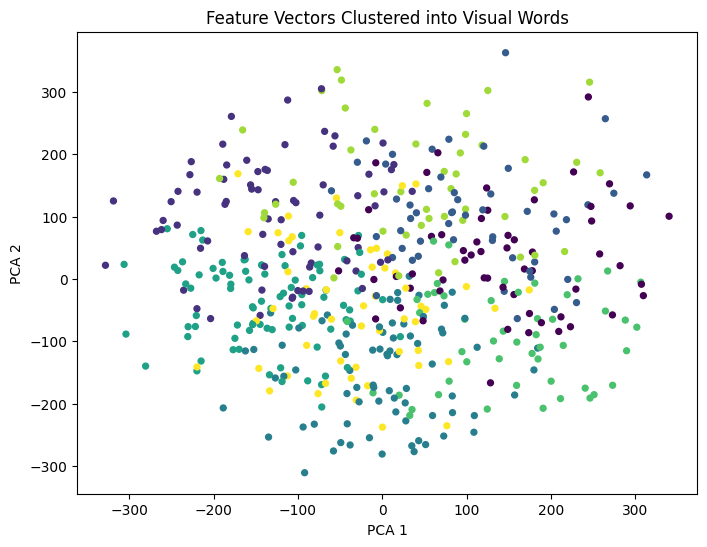

In [ ]:
pca = PCA(n_components=2)
desc_2d = pca.fit_transform(descriptors)

plt.figure(figsize=(8,6))
plt.scatter(desc_2d[:,0], desc_2d[:,1], c=cluster_labels, s=18)
plt.title('Feature Vectors Clustered into Visual Words')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.show()

## Connect This Back to the Theory

The pipeline is:

**image → keypoints → feature vectors → clusters → visual words**

In a full Bag-of-Visual-Words analysis, we would repeat this across many images and then count how often each visual word appears in each image.